##ЛР 2.1_КуриловаЕИ_ПИ-3-24

Вариант 18. Анализ данных о туристических потоках

Источник данных: UNWTO Tourism Data

Задание:

Загрузить данные о туризме (страна, год, количество туристов, доходы).

Обработать пропуски, привести к единым единицам измерения.

1. Подготовка датафрейма

In [42]:
import pandas as pd
import numpy as np

arrivals_url = "https://pre-webunwto.s3.eu-west-1.amazonaws.com/s3fs-public/2026-09/UN_Tourism_inbound_arrivals_09_2026.xlsx"
expenditure_url = "https://pre-webunwto.s3.amazonaws.com/s3fs-public/2025-12/UN_Tourism_inbound_expenditure_12_2025.xlsx"

df_arrivals = pd.read_excel(arrivals_url, sheet_name='Data')
df_expenditure = pd.read_excel(expenditure_url, sheet_name='Data')

arrivals = df_arrivals[df_arrivals['indicator_code'] == 'INBD_TRIP_TOTL_TOTL_TOUR'].copy()
expenditure = df_expenditure[df_expenditure['indicator_code'] == 'INBD_EXPD_BPAY_TOTL_VSTR'].copy()

arrivals = arrivals[arrivals['partner_area_label'] == 'World'].copy()
expenditure = expenditure[expenditure['partner_area_label'] == 'World'].copy()
print("Arrivals после фильтра:", arrivals.shape)
print("Expenditure после фильтра:", expenditure.shape)
print()

print("Единицы в arrivals:", arrivals['unit'].unique())#thousand trips
print("Единицы в expenditure:", expenditure['unit'].unique())#million US dollars
arrivals['arrivals_mln'] = arrivals['value'] / 1000   # тыс. в млн
expenditure['receipts_bln'] = expenditure['value'] / 1000  # млн в млрд

arrivals = arrivals.rename(columns={'reporter_area_label': 'country'})
expenditure = expenditure.rename(columns={'reporter_area_label': 'country'})

data = pd.merge(
    arrivals[['country', 'year', 'arrivals_mln']],
    expenditure[['country', 'year', 'receipts_bln']],
    on=['country', 'year'],
    how='outer'
)
data_raw = pd.merge(
    arrivals[['country', 'year', 'arrivals_mln']],
    expenditure[['country', 'year', 'receipts_bln']],
    on=['country', 'year'],
    how='outer'
)
print()
print(data.info())
print(data.head())

Arrivals после фильтра: (5244, 13)
Expenditure после фильтра: (4608, 13)

Единицы в arrivals: ['thousand trips']
Единицы в expenditure: ['million US dollars (nominal values)']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6074 entries, 0 to 6073
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country       6074 non-null   object 
 1   year          6074 non-null   int64  
 2   arrivals_mln  5244 non-null   float64
 3   receipts_bln  4608 non-null   float64
dtypes: float64(2), int64(1), object(1)
memory usage: 189.9+ KB
None
       country  year  arrivals_mln  receipts_bln
0  Afghanistan  2008           NaN         0.057
1  Afghanistan  2009           NaN         0.089
2  Afghanistan  2010           NaN         0.147
3  Afghanistan  2011           NaN         0.165
4  Afghanistan  2012           NaN         0.167


2. Диагностика качества данных

In [43]:
print("Пропуски:")
print(data.isnull().sum())
print("\nПроцент пропусков:")
print((data.isnull().sum() / len(data) * 100).round(2))

print(f"\nДубликаты: {data.duplicated().sum()}")

print("\nТипы данных:")
print(data.dtypes)

for col in ['arrivals_mln', 'receipts_bln']:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((data[col] < Q1 - 1.5*IQR) | (data[col] > Q3 + 1.5*IQR)).sum()
    print(f"Выбросы в {col}: {outliers}")

Пропуски:
country            0
year               0
arrivals_mln     830
receipts_bln    1466
dtype: int64

Процент пропусков:
country          0.00
year             0.00
arrivals_mln    13.66
receipts_bln    24.14
dtype: float64

Дубликаты: 0

Типы данных:
country          object
year              int64
arrivals_mln    float64
receipts_bln    float64
dtype: object
Выбросы в arrivals_mln: 775
Выбросы в receipts_bln: 624


3. Очистка данных

In [44]:
data = data.drop_duplicates()

for col in ['arrivals_mln', 'receipts_bln']:
    data[col] = data.groupby('country')[col].transform(lambda x: x.fillna(x.median()))
    data[col] = data[col].fillna(data.groupby('year')[col].transform('median'))

for col in ['arrivals_mln', 'receipts_bln']:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    data[col] = data[col].clip(lower, upper)

data['year'] = data['year'].astype(int)
data['country'] = data['country'].astype('category')

4. Визуализация ошибок до и после

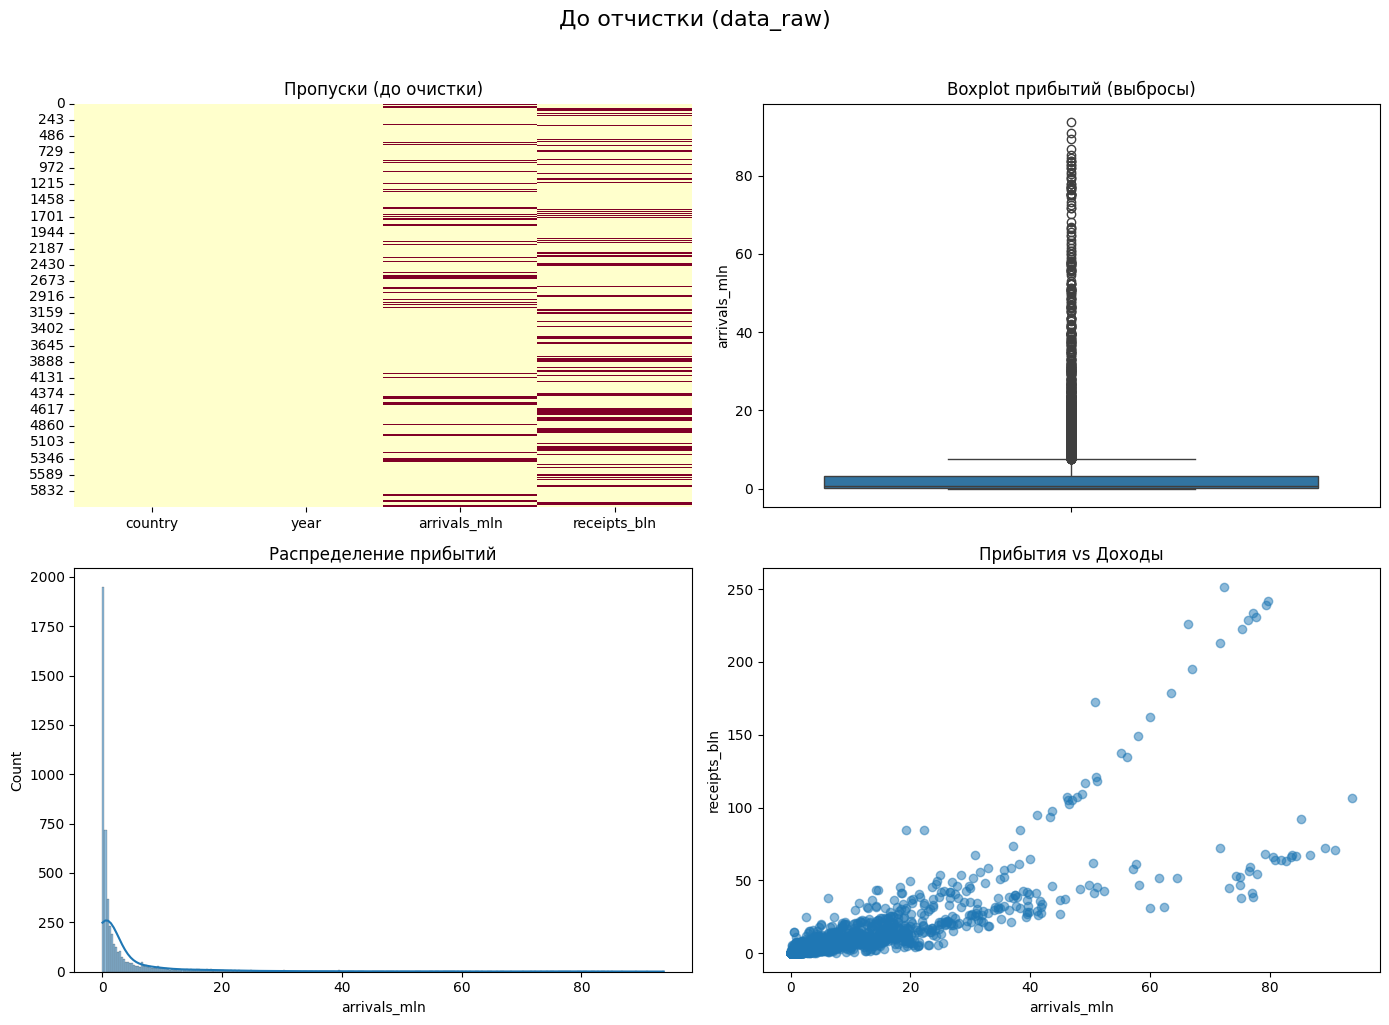

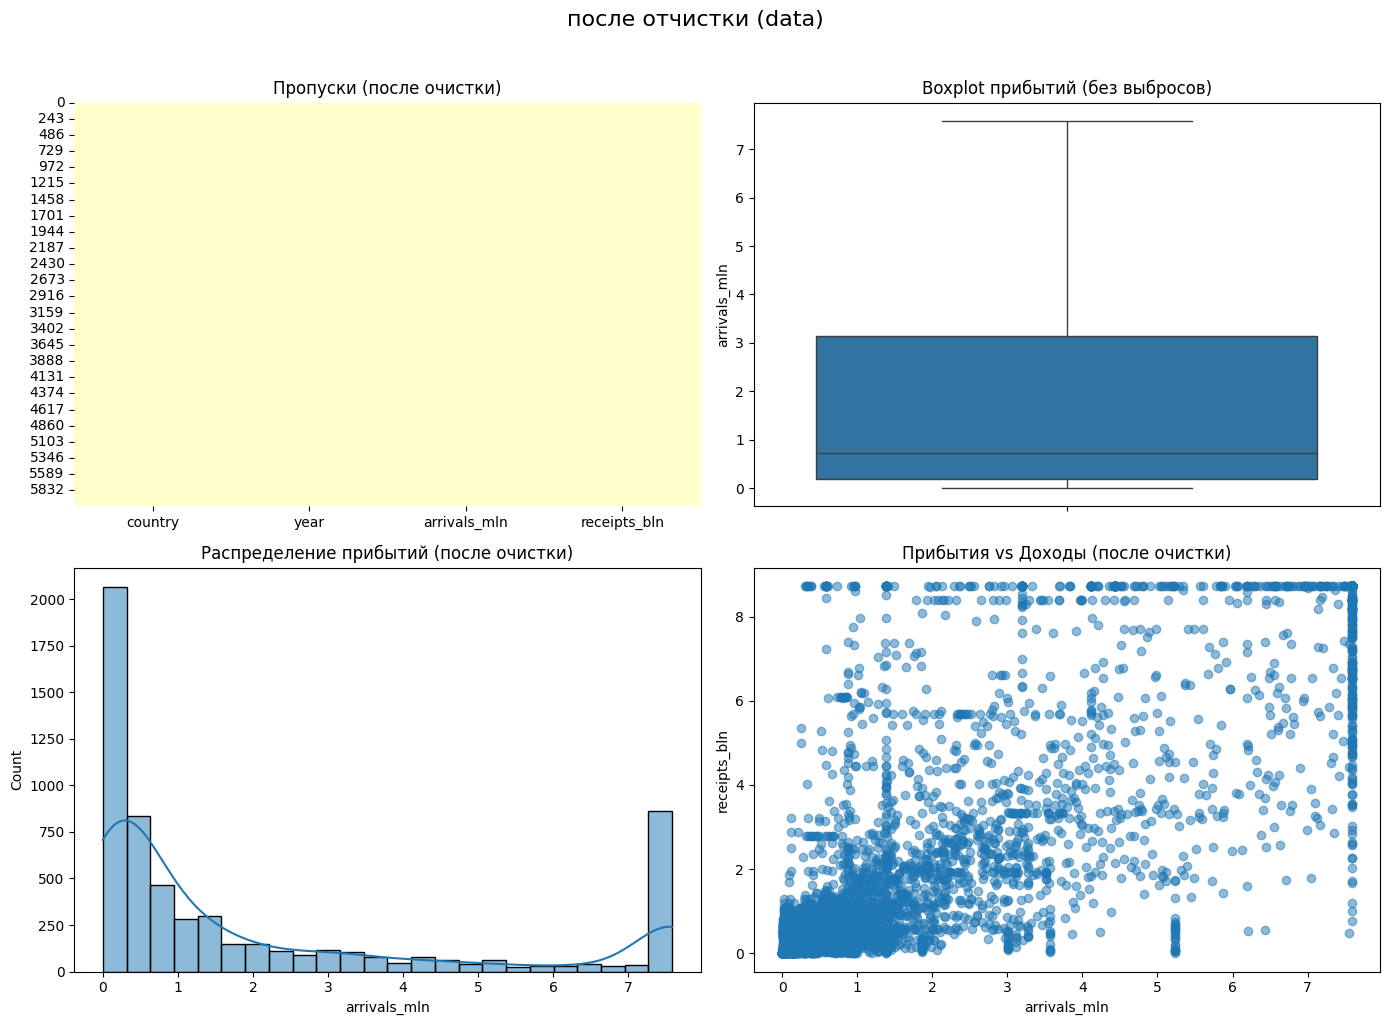

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('До отчистки (data_raw)', fontsize=16, y=1.02)

sns.heatmap(data_raw.isnull(), cbar=False, ax=axes[0, 0], cmap='YlOrRd')
axes[0, 0].set_title('Пропуски (до очистки)')

sns.boxplot(y=data_raw['arrivals_mln'], ax=axes[0, 1])
axes[0, 1].set_title('Boxplot прибытий (выбросы)')
axes[0, 1].set_ylabel('arrivals_mln')

sns.histplot(data_raw['arrivals_mln'].dropna(), kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Распределение прибытий')
axes[1, 0].set_xlabel('arrivals_mln')

axes[1, 1].scatter(data_raw['arrivals_mln'], data_raw['receipts_bln'], alpha=0.5)
axes[1, 1].set_title('Прибытия vs Доходы')
axes[1, 1].set_xlabel('arrivals_mln')
axes[1, 1].set_ylabel('receipts_bln')

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('после отчистки (data)', fontsize=16, y=1.02)

sns.heatmap(data.isnull(), cbar=False, ax=axes[0, 0], cmap='YlOrRd')
axes[0, 0].set_title('Пропуски (после очистки)')

sns.boxplot(y=data['arrivals_mln'], ax=axes[0, 1])
axes[0, 1].set_title('Boxplot прибытий (без выбросов)')
axes[0, 1].set_ylabel('arrivals_mln')

sns.histplot(data['arrivals_mln'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Распределение прибытий (после очистки)')
axes[1, 0].set_xlabel('arrivals_mln')

axes[1, 1].scatter(data['arrivals_mln'], data['receipts_bln'], alpha=0.5)
axes[1, 1].set_title('Прибытия vs Доходы (после очистки)')
axes[1, 1].set_xlabel('arrivals_mln')
axes[1, 1].set_ylabel('receipts_bln')

plt.tight_layout()
plt.show()
